# Week 6 — Classification I: Logistic Regression and K-Nearest Neighbours

## Applying classification to our molecular-properties dataset

**Classification** means predicting which category an observation belongs to. In this notebook, we use the molecular-properties dataset to classify compounds into two groups:

- **Lower LogP (`0`)**: Mannhold LogP is below the dataset median.
- **Higher LogP (`1`)**: Mannhold LogP is at or above the dataset median.

This is an educational classification target created from the available data. **It is not a bioactivity label** and does not demonstrate that the models can predict whether a molecule is biologically active.

| Term | Meaning | In this notebook |
|---|---|---|
| **Observation** | One row of data | One chemical compound |
| **Features (`X`)** | Inputs used for prediction | Molecular weight and TPSA |
| **Target (`y`)** | Category to predict | Lower or higher Mannhold LogP |
| **Model** | A rule learned from examples | Logistic Regression or KNN |
| **Training** | Learning from labelled examples | `model.fit(...)` |

We use molecular weight and topological polar surface area (TPSA) as the two features so we can visualise the models' decision boundaries. Mannhold LogP itself is **not** used as an input, because it defines the target.

## 1. Import the libraries
Like previous lectures, we also set `RANDOM_STATE = X`. Some steps (such as splitting the data) involve random choices. Fixing this "seed" makes the random choices the same every time, so everyone running the notebook gets the same results. The number 42 itself is arbitrary; any number works.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

RANDOM_STATE = 42

## 2. Load our dataset

We use `properties.csv`, the molecular-properties dataset from our project. Each row represents a compound and columns describe molecular properties.

We clean the special text value `#NUM!` by treating it as missing (`NaN`), then convert the modelling columns to numeric values. The target is created by splitting Mannhold LogP at its median. A median split gives us two reasonably balanced classes, but it also loses information about the exact LogP values.

In [2]:
df = pd.read_csv(r"C:\COLLEGE\CSC1171\Week 1\week3-DataIntro\notebooks\properties.csv")
# Replace spreadsheet-style error values with missing values.
df = df.replace("#NUM!", np.nan)
print("Dataset shape:", df.shape)
print("Available columns:", df.columns.tolist())
df.head()


Dataset shape: (15166, 34)
Available columns: ['index', 'row ID', 'Molecule', 'Molecule name', 'Mannhold LogP', 'Atomic Polarizabilities', 'Aromatic Atoms Count', 'Aromatic Bonds Count', 'Element Count', 'Bond Polarizabilities', 'Bond Count', 'Eccentric Connectivity Index', 'Fragment Complexity', 'VABC Volume Descriptor', 'Hydrogen Bond Acceptors', 'Hydrogen Bond Donors', 'Largest Chain', 'Largest Pi Chain', 'Petitjean Number', 'Rotatable Bonds Count', "Lipinski's Rule of Five", 'Topological Polar Surface Area', 'Vertex adjacency information magnitude', 'Molecular Weight', 'XLogP', 'Zagreb Index', 'Molecular Formula', 'Formal Charge', 'Formal Charge (pos)', 'Formal Charge (neg)', 'Heavy Atoms Count', 'Molar Mass', 'SP3 Character', 'Rotatable Bonds Count (non terminal)']


,index,row ID,Molecule,Molecule name,Mannhold LogP,Atomic Polarizabilities,Aromatic Atoms Count,Aromatic Bonds Count,Element Count,Bond Polarizabilities,...,XLogP,Zagreb Index,Molecular Formula,Formal Charge,Formal Charge (pos),Formal Charge (neg),Heavy Atoms Count,Molar Mass,SP3 Character,Rotatable Bonds Count (non terminal)
0,0,Row0,N,H3N,1.35,3.100379,0,0,4,1.299621,...,0.000,0,H3N,0,0,0,1,17.030525,0.000000,0
1,1,Row1,O=C(O)c1c(OC(=O)C)cccc1,C9H8O4,2.01,24.382344,6,6,21,12.577656,...,1.422,60,C9H8O4,0,0,0,13,180.157769,0.047619,3
2,2,Row2,C#C,C2H2,1.68,4.853586,0,0,4,2.186414,...,0.418,2,C2H2,0,0,0,2,26.037353,0.000000,0
3,3,Row3,P(=O)(OP(=O)(OC[C@H]1O[C@@H](n2c3ncnc(c3nc2)N)...,C10H16N5O13P3,0.25,55.084688,9,10,47,55.749312,...,-5.533,170,C10H16N5O13P3,0,0,0,31,507.181476,0.106383,8
4,4,Row4,S1C([C@H](C(=O)O)N2[C@H]1[C@H](NC(=O)[C@H](N)c...,C16H19N3O4S,2.34,50.237067,6,6,43,27.904933,...,-1.732,132,C16H19N3O4S,0,0,0,24,349.406463,0.162791,4


## 3. Explore the data

Median Mannhold LogP: 2.450
Class counts:
logp_class
Higher LogP    7897
Lower LogP     7269
Name: count, dtype: int64


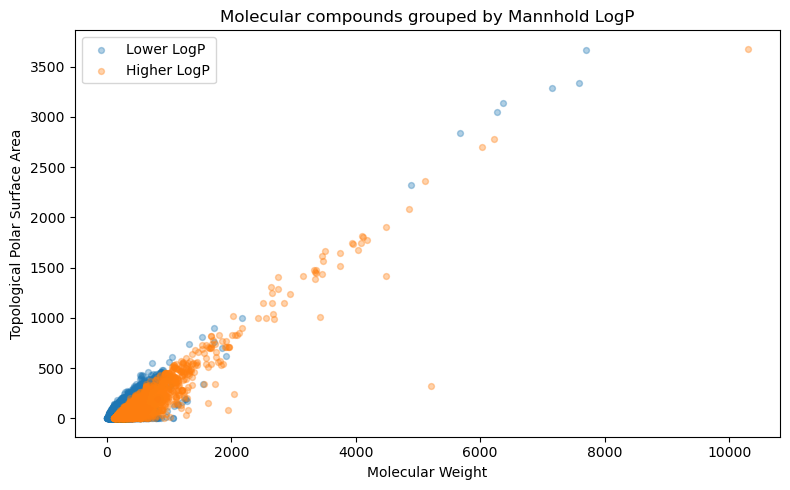

In [3]:
# Find the relevant columns using common names in the dataset.
def find_column(columns, candidates):
    for candidate in candidates:
        if candidate in columns:
            return candidate
    raise KeyError(f"Could not find any of these columns: {candidates}")

logp_col = find_column(df.columns, ["Mannhold LogP"])
mw_col = find_column(df.columns, ["Molecular Weight", "Molecular weight", "MW", "Molecular Weight (g/mol)"])
tpsa_col = find_column(df.columns, ["TPSA", "Topological Polar Surface Area", "Topological Polar Surface Area (Å²)"])

for col in [logp_col, mw_col, tpsa_col]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Require a valid LogP to create the target. Missing feature values can be imputed later.
df = df.dropna(subset=[logp_col]).copy()
logp_median = df[logp_col].median()
df["logp_class"] = (df[logp_col] >= logp_median).astype(int)
class_names = {0: "Lower LogP", 1: "Higher LogP"}

print(f"Median {logp_col}: {logp_median:.3f}")
print("Class counts:")
print(df["logp_class"].map(class_names).value_counts())

fig, ax = plt.subplots(figsize=(8, 5))
for label, name in [(0, "Lower LogP"), (1, "Higher LogP")]:
    subset = df[df["logp_class"] == label]
    ax.scatter(subset[mw_col], subset[tpsa_col], label=name, alpha=0.35, s=18)
ax.set_xlabel(mw_col)
ax.set_ylabel(tpsa_col)
ax.set_title("Molecular compounds grouped by Mannhold LogP")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Define `X` and `y`, then split the data

`X` contains two molecular descriptors: molecular weight and TPSA. `y` is the binary LogP class defined above.

We use a stratified train/test split so the proportions of lower- and higher-LogP compounds stay similar in both sets. The test set is held back for evaluation.

In [4]:
feature_columns = [mw_col, tpsa_col]
X = df[feature_columns].copy()
y = df["logp_class"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training compounds:", len(X_train))
print("Test compounds:", len(X_test))

pd.DataFrame({
    "All compounds": y.value_counts(normalize=True),
    "Training set": y_train.value_counts(normalize=True),
    "Test set": y_test.value_counts(normalize=True)
}).rename(index=class_names).round(3)

Training compounds: 11374
Test compounds: 3792


,All compounds,Training set,Test set
logp_class,,,
Higher LogP,0.521,0.521,0.521
Lower LogP,0.479,0.479,0.479


## 5. Train a Logistic Regression classifier

Logistic Regression estimates the probability that a compound belongs to the **Higher LogP** class. It then applies a threshold (0.5 by default) to choose a class.

We include median imputation because some molecular descriptors may be missing. The imputer and scaler are fitted only on the training data inside the pipeline, which helps prevent data leakage.

In [5]:
log_reg = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
)

log_reg.fit(X_train, y_train)
log_predictions = log_reg.predict(X_test)
log_probabilities = log_reg.predict_proba(X_test)[:, 1]

print("First 10 predicted classes:", log_predictions[:10])
print("First 10 probabilities of Higher LogP:", np.round(log_probabilities[:10], 2))
print("Test accuracy:", round(accuracy_score(y_test, log_predictions), 3))

First 10 predicted classes: [0 1 1 0 0 0 0 1 1 1]
First 10 probabilities of Higher LogP: [0.46 0.72 0.61 0.19 0.08 0.49 0.04 0.68 0.57 0.88]
Test accuracy: 0.834


### Interpret one prediction

The probability is the model's estimated chance that a compound belongs to the **Higher LogP** class, not a probability of biological activity. The final class is chosen using a threshold of 0.5.

In [6]:
i = 0
print("Compound features:")
display(X_test.iloc[[i]])
print("Actual class:", class_names[int(y_test.iloc[i])])
print("Probability of Higher LogP:", round(float(log_probabilities[i]), 3))
print("Predicted class:", class_names[int(log_predictions[i])])

Compound features:


,Molecular Weight,Topological Polar Surface Area
523,191.131014,20.31


Actual class: Higher LogP
Probability of Higher LogP: 0.462
Predicted class: Lower LogP


## 6. Train a K-Nearest Neighbours classifier

KNN finds the `k` most similar compounds in the training data and predicts the majority class among them. Because KNN uses distances, scaling molecular weight and TPSA is important. Median imputation and scaling are both performed within the pipeline.

In [7]:
knn = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

knn.fit(X_train, y_train)
knn_predictions = knn.predict(X_test)

print("First 10 predicted classes:", knn_predictions[:10])
print("Test accuracy:", round(accuracy_score(y_test, knn_predictions), 3))

First 10 predicted classes: [1 1 1 0 0 1 0 1 1 1]
Test accuracy: 0.87


## 7. Compare the two models

We evaluate both models on exactly the same test observations, so the comparison is fair. **Accuracy** is the proportion of test observations classified correctly. It is useful for this introduction, although it is not sufficient for every real classification problem (for example, when one class is very rare).

Keep in mind that the test set is fairly small, so a difference of a percentage point or two may just be luck of the split rather than a real difference between the models.

In [8]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN (k=5)"],
    "Test accuracy": [
        accuracy_score(y_test, log_predictions),
        accuracy_score(y_test, knn_predictions)
    ]
}).sort_values("Test accuracy", ascending=False)

results

,Model,Test accuracy
1,KNN (k=5),0.870253
0,Logistic Regression,0.833597


### Accuracy is just the first step

Accuracy tells us the proportion of compounds classified correctly, but it does not show which kinds of mistakes are made or whether one class is harder to identify. We should also consider a confusion matrix, precision, recall and cross-validation.

**Important limitation:** because the classes were created from Mannhold LogP itself, these results only evaluate classification of higher versus lower LogP. They do not predict bioactivity.

## 8. Visualise the decision boundaries

The plots show how each model separates the two LogP classes using molecular weight and TPSA. These are two-dimensional views of the models, not evidence that these two properties fully explain lipophilicity.

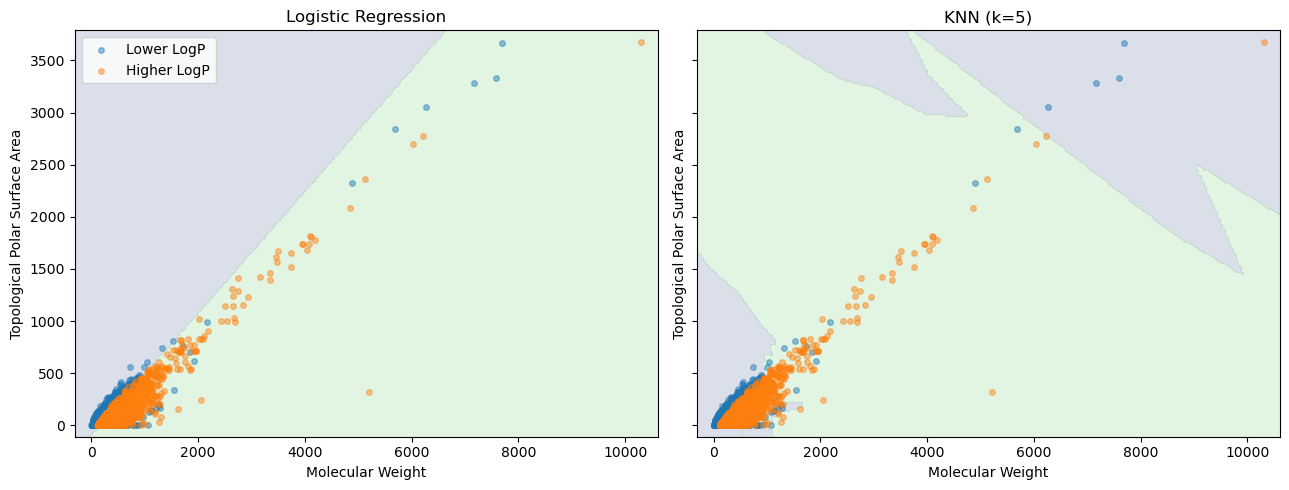

In [9]:
def plot_decision_boundary(model, X_train, y_train, title, ax):
    x_min, x_max = X_train[mw_col].min(), X_train[mw_col].max()
    y_min, y_max = X_train[tpsa_col].min(), X_train[tpsa_col].max()
    x_pad = max((x_max - x_min) * 0.03, 1)
    y_pad = max((y_max - y_min) * 0.03, 1)
    xx, yy = np.meshgrid(
        np.linspace(x_min - x_pad, x_max + x_pad, 220),
        np.linspace(y_min - y_pad, y_max + y_pad, 220)
    )
    grid = pd.DataFrame({mw_col: xx.ravel(), tpsa_col: yy.ravel()})
    zz = model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, zz, alpha=0.18, levels=[-0.5, 0.5, 1.5])
    for label, name in [(0, "Lower LogP"), (1, "Higher LogP")]:
        subset = X_train.loc[y_train == label]
        ax.scatter(subset[mw_col], subset[tpsa_col], label=name, alpha=0.45, s=16)
    ax.set_xlabel(mw_col)
    ax.set_ylabel(tpsa_col)
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
plot_decision_boundary(log_reg, X_train, y_train, "Logistic Regression", axes[0])
plot_decision_boundary(knn, X_train, y_train, "KNN (k=5)", axes[1])
axes[0].legend()
plt.tight_layout()
plt.show()

## 9. What changes when we change `k`?

In KNN, `k` is the number of neighbouring compounds that vote. Small `k` can produce irregular boundaries and overfit; larger `k` smooths the boundary but may underfit. Compare the test accuracy for several values of `k`.

In [10]:
k_values = [1, 5, 20]
knn_models = {}
k_results = []

for k in k_values:
    model = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    knn_models[k] = model
    k_results.append({
        "k": k,
        "Test accuracy": accuracy_score(y_test, predictions)
    })

pd.DataFrame(k_results)

,k,Test accuracy
0,1,0.856804
1,5,0.870253
2,20,0.866825


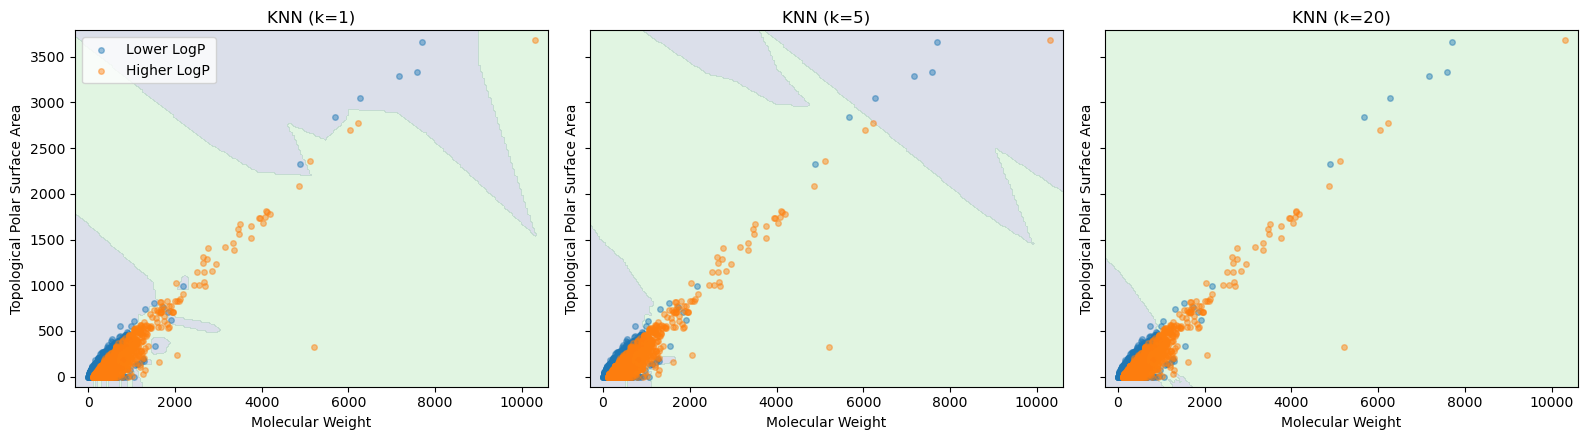

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
for ax, k in zip(axes, k_values):
    plot_decision_boundary(knn_models[k], X_train, y_train, f"KNN (k={k})", ax)
axes[0].legend()
plt.tight_layout()
plt.show()

### Optional extension

Try adding other molecular descriptors (for example, hydrogen-bond acceptors or rotatable bonds) and compare the models. If you add more than two features, the decision-boundary plotting function will need to remain based on a two-feature model or be adapted.

## Key takeaways

| | **Logistic Regression** | **K-Nearest Neighbours (KNN)** |
|---|---|---|
| **Main idea** | Learns feature weights and estimates a class probability | Finds the `k` most similar training compounds and takes a majority vote |
| **Output** | Probability for the Higher LogP class, then a class using a threshold | Predicted class from neighbour votes |
| **Decision boundary** | Straight line in this two-feature view | Can be curved and irregular |
| **Setting we choose** | Classification threshold and model settings | `k`, the number of neighbours |
| **Scaling** | Helpful | Important because KNN uses distances |

**Interpretation caution:** This notebook creates classes from the median Mannhold LogP. It is a classification exercise using our dataset, not a bioactivity prediction model. A genuine bioactivity classifier would require a measured bioactivity endpoint and clearly defined active/inactive labels.